# Construcción autorizada y dinámica poblacional en Costa Rica
**Adrian Rojas Rivera · Big Data · Proyecto final**

El flujo reproducible se ejecuta con `programa.py`: preparación de Excel en Spark, dos regresores, corpus PEN, Hugging Face, PostgreSQL y Elasticsearch. Este cuaderno muestra sus resultados y comprueba los destinos reales. Las explicaciones completas están en el manual y `doc/Analisis_resultados.md`.

Objetivo predictivo: estimar el área autorizada del año siguiente. Objetivo documental: recuperar fragmentos históricos en español y comparar BM25 con vectores sobre el mismo corpus. Los permisos no equivalen a obras terminadas.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'config').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
from functions.entorno import iniciar_spark
from functions.materializacion import es_request, JDBC, PROPS
O = ROOT / 'output'
spark = iniciar_spark()
spark.sparkContext.setLogLevel('ERROR')
print('Spark', spark.version)
print('Etapas del programa: preparar, entrenar, embeddings, cargar, buscar, dashboard, verificar')


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/29 16:26:35 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.1
Etapas del programa: preparar, entrenar, embeddings, cargar, buscar, dashboard, verificar


## 1. Fuentes, esquema y cruce en Spark
Construcción 2015–2024 y población C4 del INEC. Se agregan Grecia/Río Cuarto, Puntarenas/Monteverde y Golfito/Puerto Jiménez. Los signos se conservan como ausencia, sin imputación automática a cero.

In [2]:
etl = json.loads((O / 'etl.json').read_text())
display(pd.DataFrame(list(etl['filas'].items()), columns=['conjunto','filas']))
df = spark.read.parquet(str(ROOT/'data/preparados/integrado'))
df.printSchema()
display(df.filter('anio=2024').orderBy('codigo_agrupacion').limit(5).toPandas())
display(pd.read_csv(O/'reconciliacion_nacional.csv'))

,conjunto,filas
0,territorios,81
1,construccion_cantonal,818
2,poblacion_cantonal,840
3,destinos_cantonales,12121
4,construccion_agrupada,810
5,poblacion_agrupada,810
6,integrado,810


root
 |-- codigo_agrupacion: string (nullable = true)
 |-- anio: integer (nullable = true)
 |-- obras_total: long (nullable = true)
 |-- area_m2: double (nullable = true)
 |-- valor_miles_colones: double (nullable = true)
 |-- obras_nuevas: long (nullable = true)
 |-- area_nueva_m2: double (nullable = true)
 |-- valor_nueva_miles: double (nullable = true)
 |-- obras_ampliacion: long (nullable = true)
 |-- area_ampliacion_m2: double (nullable = true)
 |-- valor_ampliacion_miles: double (nullable = true)
 |-- obras_reparacion: long (nullable = true)
 |-- valor_reparacion_miles: double (nullable = true)
 |-- codigos_construccion: string (nullable = true)
 |-- origen_construccion: string (nullable = true)
 |-- poblacion: double (nullable = true)
 |-- hombres: double (nullable = true)
 |-- mujeres: double (nullable = true)
 |-- codigos_poblacion: string (nullable = true)
 |-- origen_poblacion: string (nullable = true)
 |-- agrupacion: string (nullable = true)
 |-- provincia: string (nullabl

,codigo_agrupacion,anio,obras_total,area_m2,valor_miles_colones,obras_nuevas,area_nueva_m2,valor_nueva_miles,obras_ampliacion,area_ampliacion_m2,...,codigos_construccion,origen_construccion,poblacion,hombres,mujeres,codigos_poblacion,origen_poblacion,agrupacion,provincia,area_por_habitante
0,101,2024,679,101064.0,3.786125e+07,451,92295.0,3.041396e+07,71,8769.0,...,101,Construccion_2024.xlsx:2024:61,352298.484915,173214.913915,179083.571000,101,Poblacion_2000_2050_INEC.xlsx:C4:F180,San José,San José,0.286870
1,102,2024,716,94682.0,4.238856e+07,445,89614.0,3.268190e+07,54,5068.0,...,102,Construccion_2024.xlsx:2024:82,70903.348646,34688.739966,36214.608680,102,Poblacion_2000_2050_INEC.xlsx:C4:F181,Escazú,San José,1.335367
2,103,2024,331,21038.0,7.540494e+06,189,15517.0,5.059534e+06,78,5521.0,...,103,Construccion_2024.xlsx:2024:102,244173.396490,120840.223323,123333.173167,103,Poblacion_2000_2050_INEC.xlsx:C4:F182,Desamparados,San José,0.086160
3,104,2024,298,17771.0,4.903360e+06,241,15583.0,4.258897e+06,44,2188.0,...,104,Construccion_2024.xlsx:2024:124,39069.282619,19467.623648,19601.658972,104,Poblacion_2000_2050_INEC.xlsx:C4:F183,Puriscal,San José,0.454859
4,105,2024,199,9192.0,2.967183e+06,157,8383.0,2.554046e+06,19,809.0,...,105,Construccion_2024.xlsx:2024:145,17990.175683,9037.987689,8952.187994,105,Poblacion_2000_2050_INEC.xlsx:C4:F184,Tarrazú,San José,0.510946


,anio,obras_total_calculado,area_m2_calculado,valor_miles_colones_calculado,area_m2,obras_total,valor_miles_colones
0,2015,33514,3772941.0,9.754712e+08,3772941.0,33514.0,9.754712e+08
1,2016,34909,3684089.0,9.840755e+08,3684089.0,34909.0,9.840755e+08
2,2017,30507,3498161.0,9.540354e+08,3498161.0,30507.0,9.540354e+08
3,2018,30347,3030842.0,9.012443e+08,3030842.0,30347.0,9.012443e+08
4,2019,34419,3631154.0,1.169676e+09,3631154.0,34419.0,1.169676e+09
5,2020,30675,3405104.0,9.785299e+08,3405104.0,30675.0,9.785299e+08
6,2021,39960,3681777.0,1.134344e+09,3681777.0,39960.0,1.134344e+09
7,2022,43422,3918842.0,1.361854e+09,3918842.0,43422.0,1.361854e+09
8,2023,40440,3692085.0,1.242705e+09,3692085.0,40440.0,1.242705e+09
9,2024,40351,3684654.0,1.212840e+09,3684654.0,40351.0,1.212840e+09


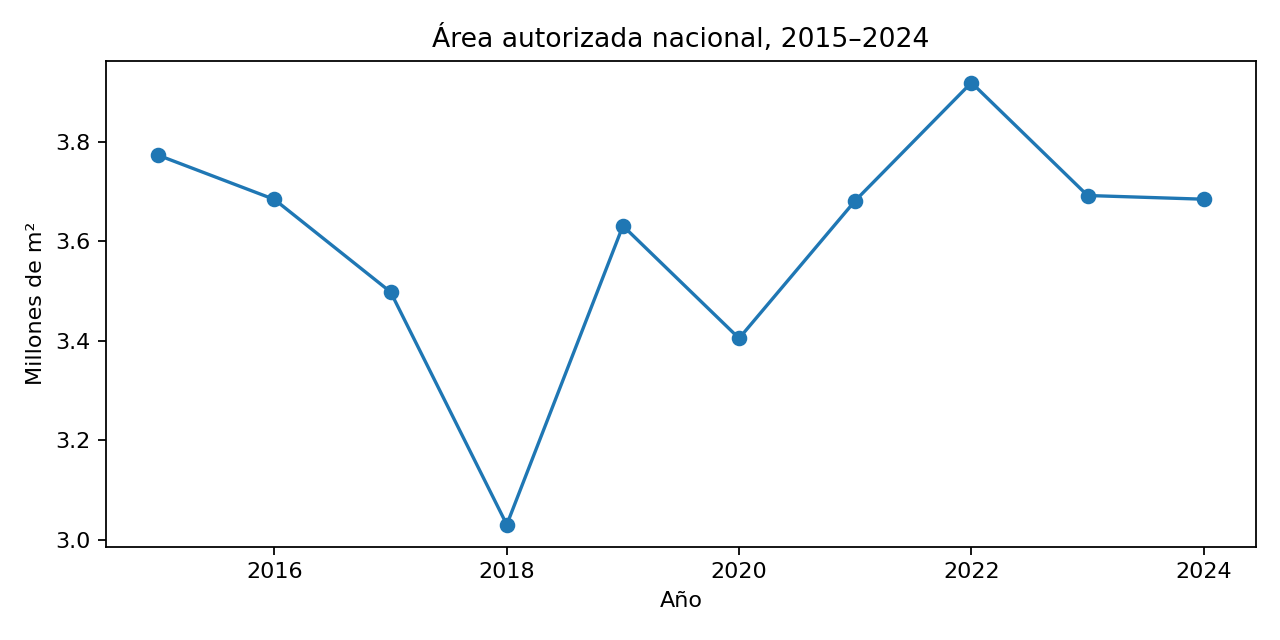

In [3]:
display(Image(filename=str(O/'graficos/evolucion_area.png')))

## 2. Diseño temporal y K-fold
Los predictores usan únicamente los dos años anteriores al objetivo. K-fold agrupa territorios dentro de 2017–2021 y mezcla esos años: es un diagnóstico territorial, no una validación cronológica. La validación temporal es 2022 y la prueba reservada 2023–2024. Las versiones revisadas de las fuentes limitan la interpretación como pronóstico en tiempo real.

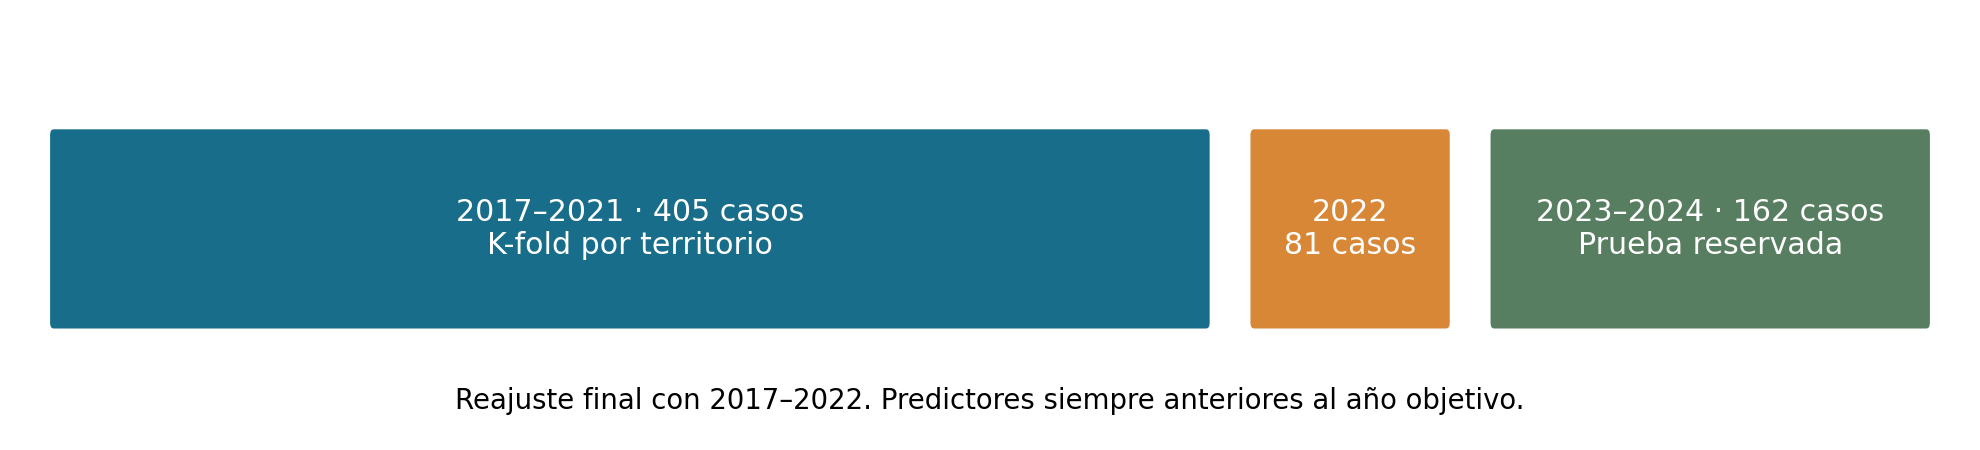

,fold,filas,territorios
0,0,155,31
1,1,160,32
2,2,90,18


,codigo_agrupacion,agrupacion,provincia,anio_objetivo,anio_datos,area_m2,area_t,area_t_menos1,poblacion_t,crecimiento_poblacion,log_area_t,log_area_t_menos1,log_obras_t,log_poblacion_t
0,101,San José,San José,2017,2016,91069.0,95887.0,192570.0,341636.109248,0.007682,11.470936,12.168220,5.986452,12.741504
1,102,Escazú,San José,2017,2016,140582.0,164571.0,271341.0,67765.111451,0.009462,12.011103,12.511135,6.311735,11.123818
2,103,Desamparados,San José,2017,2016,24037.0,49430.0,24312.0,233050.519001,0.009977,10.808333,10.098766,6.376727,12.359015
3,104,Puriscal,San José,2017,2016,21797.0,25208.0,24998.0,37333.276634,0.009975,10.134956,10.126591,5.998937,10.527667
4,105,Tarrazú,San José,2017,2016,8054.0,9410.0,8788.0,17535.388274,0.008337,9.149634,9.081256,4.983607,9.772033


In [4]:
display(Image(filename=str(O/'graficos/evaluacion_temporal.png')))
display(pd.read_csv(O/'cv_particiones.csv'))
display(pd.read_csv(O/'casos_supervisados.csv', dtype={'codigo_agrupacion':str}).head())

## 3. Pipelines y selección
VectorAssembler, StandardScaler, regresor y transformación inversa del objetivo logarítmico. El escalador se ajusta dentro de cada fold. Ambos regresores comparan cuatro configuraciones; se selecciona por RMSE en m². La referencia de persistencia usa el área del año anterior.

In [5]:
display(pd.read_csv(O/'validacion_cruzada.csv'))
display(pd.read_csv(O/'validacion_modelos.csv'))
display(Markdown('**Decisión previa a la prueba:** ' + json.loads((O/'decisiones_antes_prueba.json').read_text())['criterio']))

,modelo,configuracion,parametros,rmse_cv_m2,std_rmse_folds,seleccionado
0,lineal,0,"{""regParam"": 0.01, ""elasticNetParam"": 0.0}",29676.676698,7833.757549,True
1,lineal,1,"{""regParam"": 0.01, ""elasticNetParam"": 0.5}",29786.852520,7968.582900,False
2,lineal,2,"{""regParam"": 0.1, ""elasticNetParam"": 0.0}",30613.849095,8638.479156,False
3,lineal,3,"{""regParam"": 0.1, ""elasticNetParam"": 0.5}",31395.449501,9576.658849,False
4,bosque,0,"{""maxDepth"": 3, ""minInstancesPerNode"": 4}",35396.521843,13909.534471,False
5,bosque,1,"{""maxDepth"": 3, ""minInstancesPerNode"": 8}",35462.247503,13997.448787,False
6,bosque,2,"{""maxDepth"": 5, ""minInstancesPerNode"": 4}",34463.013981,12539.630044,True
7,bosque,3,"{""maxDepth"": 5, ""minInstancesPerNode"": 8}",34602.835280,12707.222766,False


,modelo,particion,n,mae_m2,rmse_m2,sesgo_m2
0,lineal,validacion_2022,81,18215.170823,37627.279956,-10324.880078
1,lineal,entrenamiento_2017_2021,405,15019.613773,31996.147163,-4976.357456
2,bosque,validacion_2022,81,19005.698740,38911.727925,-10875.295084
3,bosque,entrenamiento_2017_2021,405,12834.768119,28612.462006,-5055.542332
4,persistencia,validacion_2022,81,16835.765432,34378.253667,-2926.728395


**Decisión previa a la prueba:** RMSE m²; CV por territorios 2017-2021 para hiperparámetros; 2022 para familia; prueba 2023-2024 intacta

## 4. Prueba final y diferencias
La lineal obtiene menor MAE y RMSE global en 2023–2024. En 2022 la persistencia había superado a ambos regresores; en 2023 aún conserva menor MAE que la lineal. La comparación no acredita superioridad universal. El historial de áreas domina las dos representaciones; coeficientes e importancias no son efectos causales.

,modelo,particion,n,mae_m2,rmse_m2,sesgo_m2
0,lineal,prueba_2023_2024,162,11790.675917,22202.135442,-3780.062503
1,lineal,2023,81,13987.316140,24798.699437,-3585.278347
2,lineal,2024,81,9594.035695,19258.612166,-3974.846660
3,bosque,prueba_2023_2024,162,13783.175405,26836.638174,-4730.987256
4,bosque,2023,81,16429.444045,30553.128291,-4860.393369
5,bosque,2024,81,11136.906765,22514.809539,-4601.581143
6,persistencia,prueba_2023_2024,162,12410.703704,24385.116623,1445.604938
7,persistencia,2023,81,13127.543210,27262.364095,2799.469136
8,persistencia,2024,81,11693.864198,21119.453814,91.740741


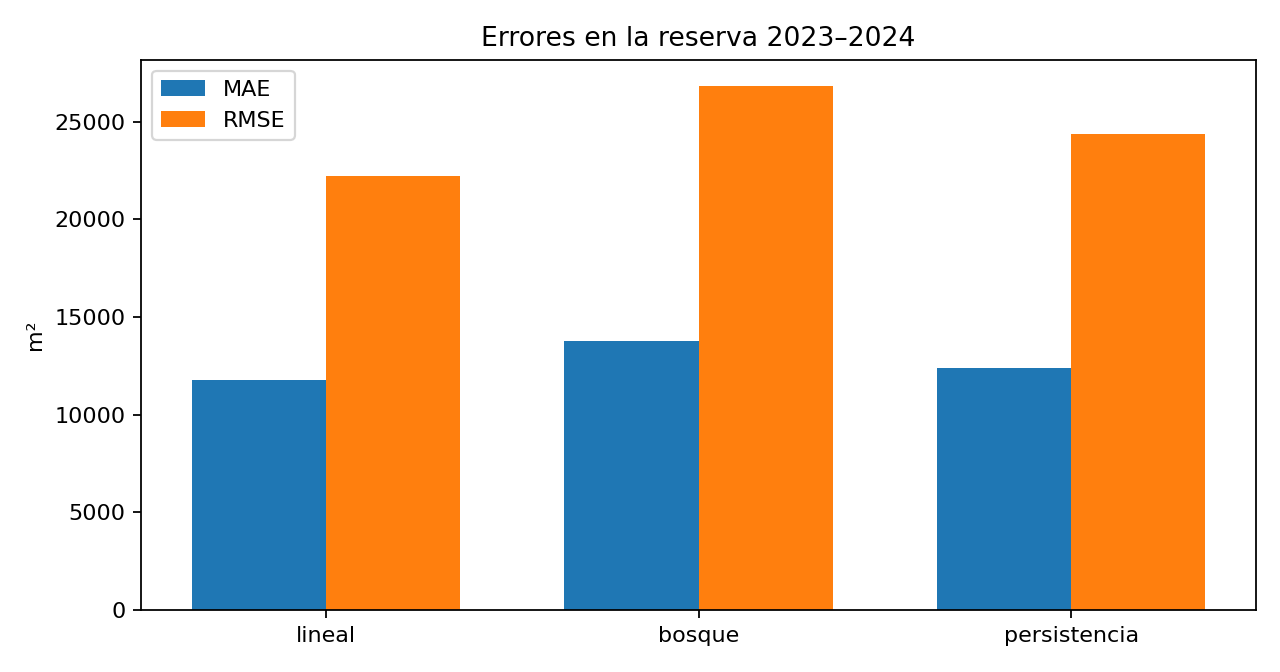

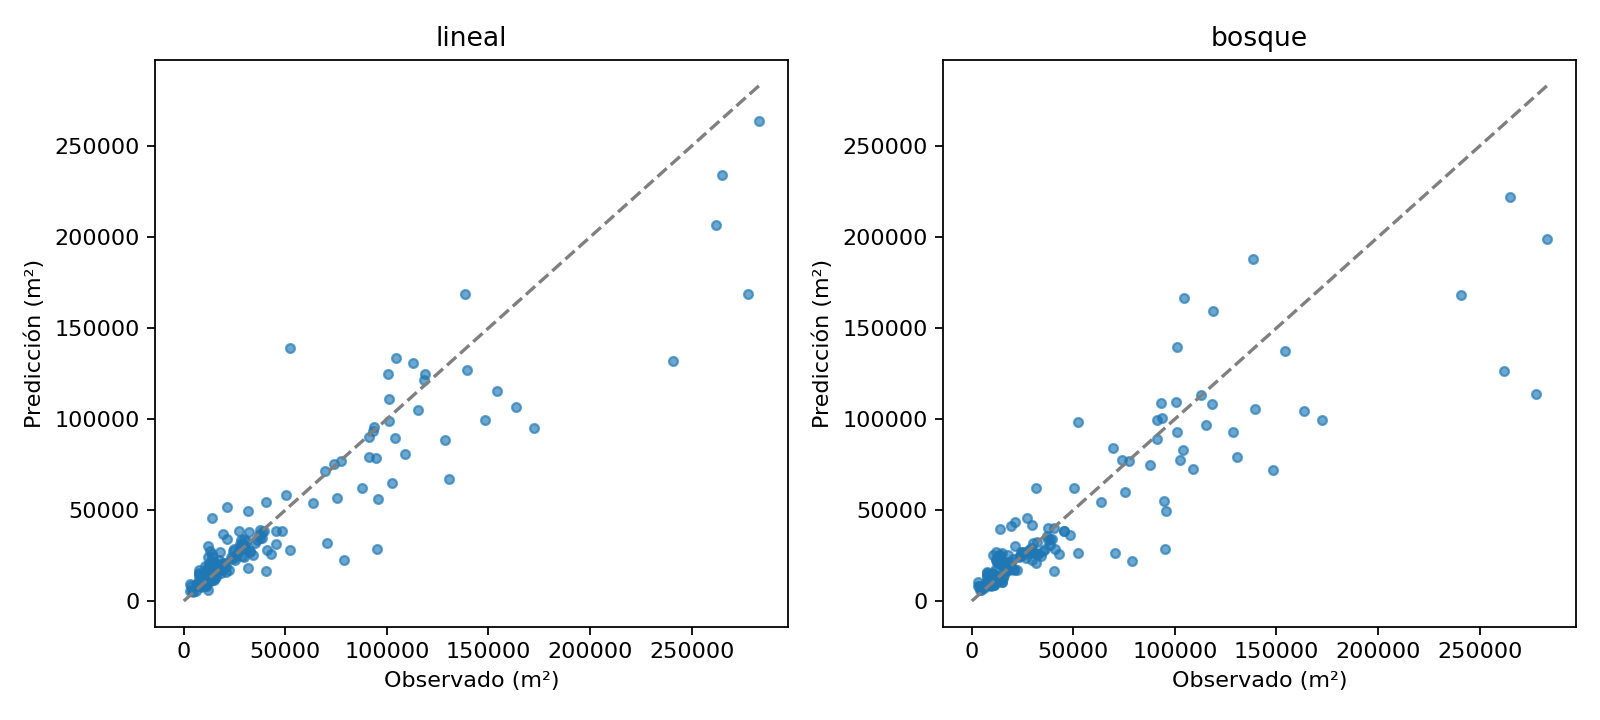

,modelo,codigo_agrupacion,agrupacion,provincia,n,mae_m2,sesgo_m2
0,bosque,503,Santa Cruz,Guanacaste,2,149908.883104,-149908.883104
1,bosque,201,Alajuela,Alajuela,2,63632.764187,-63632.764187
2,bosque,301,Cartago,Cartago,2,61230.401774,-11665.123427
3,bosque,203,Grecia y Río Cuarto,Alajuela,2,46541.171086,-46541.171086
4,bosque,102,Escazú,San José,2,42667.978279,3007.593363
5,bosque,109,Santa Ana,San José,2,41415.218786,-41415.218786
6,bosque,404,Santa Bárbara,Heredia,2,41246.189682,-15523.795920
7,bosque,210,San Carlos,Alajuela,2,39567.408250,22695.528913
8,bosque,101,San José,San José,2,39409.861315,39409.861315
9,bosque,407,Belén,Heredia,2,39252.032326,-39252.032326


In [6]:
display(pd.read_csv(O/'metricas_modelos.csv'))
display(Image(filename=str(O/'graficos/errores_modelos.png')))
display(Image(filename=str(O/'graficos/observado_predicho.png')))
display(pd.read_csv(O/'errores_territorio.csv', dtype={'codigo_agrupacion':str}).head(10))

## 5. Feedback y corpus PEN
La preparación conserva referencias de documento, año y página. El límite de 400 tokens incluye prefijo y tokens especiales. El modelo E5 tiene 384 dimensiones; se usan passage: y query:. Se excluyen párrafos dudosos con un registro de cambios. Los anexos 2021 se conservan con maquetación textual por página y requieren revisar el PDF para interpretar filas municipales.

In [7]:
emb = json.loads((O/'embeddings.json').read_text())
display(pd.DataFrame({'documento':list(emb['por_documento']), 'fragmentos':list(emb['por_documento'].values())}))
print('Páginas:',emb['paginas_originales'],'incluidas:',emb['paginas_incluidas'],'máximo tokens:',emb['tokens_max'])
with np.load(O/'embeddings.npz', allow_pickle=False) as vv:
    print('Forma:',vv['vectores'].shape,'Normas:',np.linalg.norm(vv['vectores'],axis=1).min(),np.linalg.norm(vv['vectores'],axis=1).max())
frags = [json.loads(line) for line in (O/'fragmentos.jsonl').read_text().splitlines()]
f = next(x for x in frags if x['documento_id']=='PEN_2017_CIUDADES' and x['pagina_pdf']==40)
display(Markdown(f"**{f['documento_id']} · página PDF {f['pagina_pdf']}**\n\n{f['texto']}\n\n[Fuente]({f['url_fuente']})"))

,documento,fragmentos
0,PEN_2017_CIUDADES,65
1,PEN_2018_GAM,90
2,PEN_2021_TERRITORIO,99
3,PEN_2023_REGULACION,44


Páginas: 232 incluidas: 194 máximo tokens: 397
Forma: (298, 384) Normas: 0.9999999 1.0000001


**PEN_2017_CIUDADES · página PDF 40**

En el caso del cantón de Pococí, las principales amenazas son hidrometeorológicas y sísmicas. Los riesgos de deslizamientos son reducidos en la mayor parte del cantón, considerando la topografía preponderantemente plana de Pococí, únicamente el sector sur, donde hay mayores pendientes, existe un riesgo más alto a que se presenten este tipo de eventos.

El Cantón de Pococí, posee una red fluvial bien definida, la misma cuenta con un grupo de ríos y quebradas que se pueden considerar el punto focal de las amenazas hidrometeorológicas del cantón. Dicha red de drenaje est á compuesta principalmente por los ríos Chirripó, Toro Amarillo, Guápiles, Santa Clara, Tortuguero, Desenredito, Desenredado y Colorado.

La ocupación de las planicies de inundación, el desarrollo agropecuario inapropiado, el deterioro de las cuencas hidrográficas en las partes altas y el crecimiento urbano en forma desordenado pueden agravar el impacto de las inundaciones sobre las comunidades.

[Fuente](https://repositorio.conare.ac.cr/items/9ece2768-86f1-445e-9dae-0193d2f31606)

## 6. Bases de datos reales
Se releen las tablas SQL y se consultan ambos índices. La ejecución repetida conserva conteos y contenidos. Los nombres del esquema y de los índices pertenecen exclusivamente a este proyecto.

In [8]:
for table in ['construccion_cantonal','poblacion_cantonal','integrado','predicciones']:
    stored = spark.read.jdbc(JDBC, 'proyecto.'+table, properties=PROPS)
    print('PostgreSQL',table,stored.count())
print('Elasticsearch texto:',es_request('GET','cp-texto/_count')['count'])
print('Elasticsearch vectores:',es_request('GET','cp-vector/_count')['count'])
print('Mapping del vector:',es_request('GET','cp-vector/_mapping')['cp-vector']['mappings']['properties']['embedding'])

PostgreSQL construccion_cantonal 818
PostgreSQL poblacion_cantonal 840
PostgreSQL integrado 810
PostgreSQL predicciones 324


Elasticsearch texto: 298
Elasticsearch vectores: 298
Mapping del vector: {'type': 'dense_vector', 'dims': 384, 'index': True, 'similarity': 'cosine', 'index_options': {'type': 'hnsw', 'm': 16, 'ef_construction': 100}}


## 7. Comparación de búsquedas
Se revisaron 110 pares consulta-fragmento sin método ni score durante la lectura. Grados: 2 respuesta directa, 1 contexto parcial, 0 no pertinente. Hay cuatro consultas de desarrollo, ocho de reserva y dos controles sin respuesta. No hay segundo anotador independiente ni etiquetas exhaustivas del corpus.

,grupo,metodo,precision_5_estricta,precision_5_contextual,reciproco_primer_relevante
0,control_sin_respuesta,texto,0.00,0.00,0.000
1,control_sin_respuesta,vector,0.00,0.00,0.000
2,desarrollo,texto,0.35,0.55,0.625
3,desarrollo,vector,0.60,0.90,1.000
4,reserva,texto,0.30,0.85,0.650
5,reserva,vector,0.30,0.80,0.625


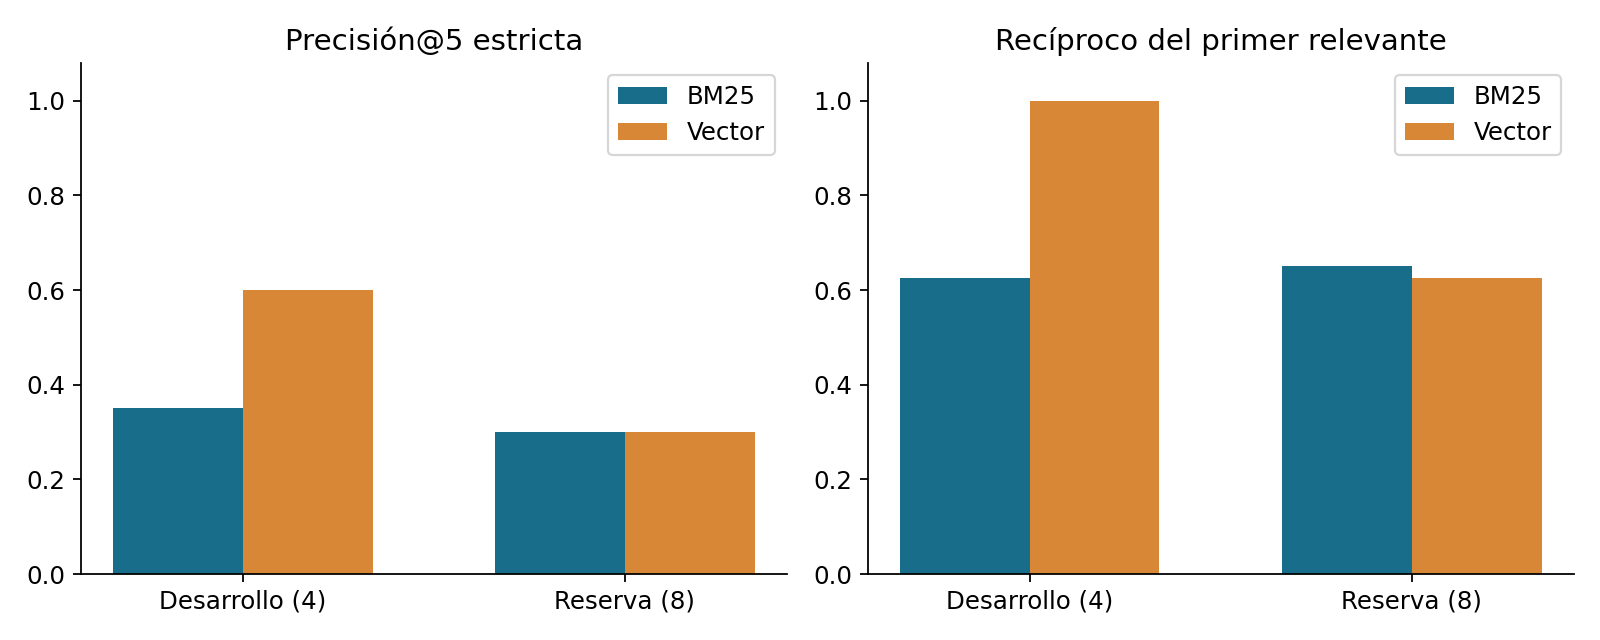

,consulta,metodo,rango,documento,pagina,fragmento_id
0,Q01,texto,1,PEN_2023_REGULACION,8,PEN_2023_REGULACION_p008_321af24f7234ded8
1,Q01,texto,2,PEN_2023_REGULACION,26,PEN_2023_REGULACION_p026_e2d4af5f49ecb86f
2,Q01,texto,3,PEN_2023_REGULACION,12,PEN_2023_REGULACION_p012_38547c643d582416
3,Q01,texto,4,PEN_2023_REGULACION,18,PEN_2023_REGULACION_p018_a823bb974689858a
4,Q01,texto,5,PEN_2023_REGULACION,21,PEN_2023_REGULACION_p021_b60a1a3c46bd1ce0


,consulta,metodo,rango,documento,pagina,fragmento_id
0,Q01,vector,1,PEN_2023_REGULACION,8,PEN_2023_REGULACION_p008_01b1ea6d61dbbe75
1,Q01,vector,2,PEN_2023_REGULACION,22,PEN_2023_REGULACION_p022_625d8635629e2e77
2,Q01,vector,3,PEN_2017_CIUDADES,41,PEN_2017_CIUDADES_p041_9f3c1ab2a4f1cad0
3,Q01,vector,4,PEN_2023_REGULACION,17,PEN_2023_REGULACION_p017_aabc9107fdcf69a2
4,Q01,vector,5,PEN_2023_REGULACION,12,PEN_2023_REGULACION_p012_38547c643d582416


,consulta,metodo,rango,documento,pagina,fragmento_id
0,Q03,texto,1,PEN_2017_CIUDADES,40,PEN_2017_CIUDADES_p040_b40636cf34a2894a
1,Q03,texto,2,PEN_2017_CIUDADES,38,PEN_2017_CIUDADES_p038_32cdc410b7c9f278
2,Q03,texto,3,PEN_2017_CIUDADES,40,PEN_2017_CIUDADES_p040_5ad4e58528c3d2a3
3,Q03,texto,4,PEN_2023_REGULACION,26,PEN_2023_REGULACION_p026_e2d4af5f49ecb86f
4,Q03,texto,5,PEN_2023_REGULACION,16,PEN_2023_REGULACION_p016_1c17333e0b44c5f0


,consulta,metodo,rango,documento,pagina,fragmento_id
0,Q03,vector,1,PEN_2017_CIUDADES,40,PEN_2017_CIUDADES_p040_b40636cf34a2894a
1,Q03,vector,2,PEN_2017_CIUDADES,42,PEN_2017_CIUDADES_p042_670e49678eac4bec
2,Q03,vector,3,PEN_2017_CIUDADES,14,PEN_2017_CIUDADES_p014_0bee2c28c9ca1e4f
3,Q03,vector,4,PEN_2017_CIUDADES,40,PEN_2017_CIUDADES_p040_5ad4e58528c3d2a3
4,Q03,vector,5,PEN_2017_CIUDADES,39,PEN_2017_CIUDADES_p039_37aed3503b8a9f59


,consulta,metodo,rango,documento,pagina,fragmento_id
0,Q11,texto,1,PEN_2018_GAM,39,PEN_2018_GAM_p039_be47911d76120a63
1,Q11,texto,2,PEN_2018_GAM,39,PEN_2018_GAM_p039_c0ceda5ebb78dd7b
2,Q11,texto,3,PEN_2017_CIUDADES,15,PEN_2017_CIUDADES_p015_0412336de4408457
3,Q11,texto,4,PEN_2017_CIUDADES,15,PEN_2017_CIUDADES_p015_921c2c02d25752ec
4,Q11,texto,5,PEN_2021_TERRITORIO,68,PEN_2021_TERRITORIO_p068_e9f77e2f1d9e8267


,consulta,metodo,rango,documento,pagina,fragmento_id
0,Q11,vector,1,PEN_2017_CIUDADES,15,PEN_2017_CIUDADES_p015_0412336de4408457
1,Q11,vector,2,PEN_2021_TERRITORIO,68,PEN_2021_TERRITORIO_p068_e9f77e2f1d9e8267
2,Q11,vector,3,PEN_2021_TERRITORIO,68,PEN_2021_TERRITORIO_p068_ec0f725c811d60ca
3,Q11,vector,4,PEN_2018_GAM,39,PEN_2018_GAM_p039_be47911d76120a63
4,Q11,vector,5,PEN_2018_GAM,39,PEN_2018_GAM_p039_c0ceda5ebb78dd7b


In [9]:
display(pd.read_csv(O/'resumen_busqueda.csv'))
display(Image(filename=str(O/'graficos/comparacion_busquedas.png')))
results = json.loads((O/'resultados_busqueda.json').read_text())
for r in results:
    if r['id'] in ['Q01','Q03','Q11']:
        display(pd.DataFrame([{'consulta':r['id'],'metodo':r['metodo'],'rango':x['rango'],'documento':x['documento_id'],'pagina':x['pagina_pdf'],'fragmento_id':x['fragmento_id']} for x in r['resultados']]))

En la reserva, ambos métodos alcanzan precisión@5 estricta de 0,30; el MRR es 0,650 para BM25 y 0,625 para vector. La ventaja semántica de desarrollo no se generaliza automáticamente. Ambos retornan vecinos para los controles sin evidencia; no hay abstención calibrada.

## 8. Kibana y reproducción
El dashboard ofrece cinco visualizaciones con filtros de periodo y datos reales. Consultas reproducibles: `elastic/Consultas_Kibana.http`. El notebook no vuelve a entrenar al abrirse: los programas de cada etapa y sus instrucciones están en el README.

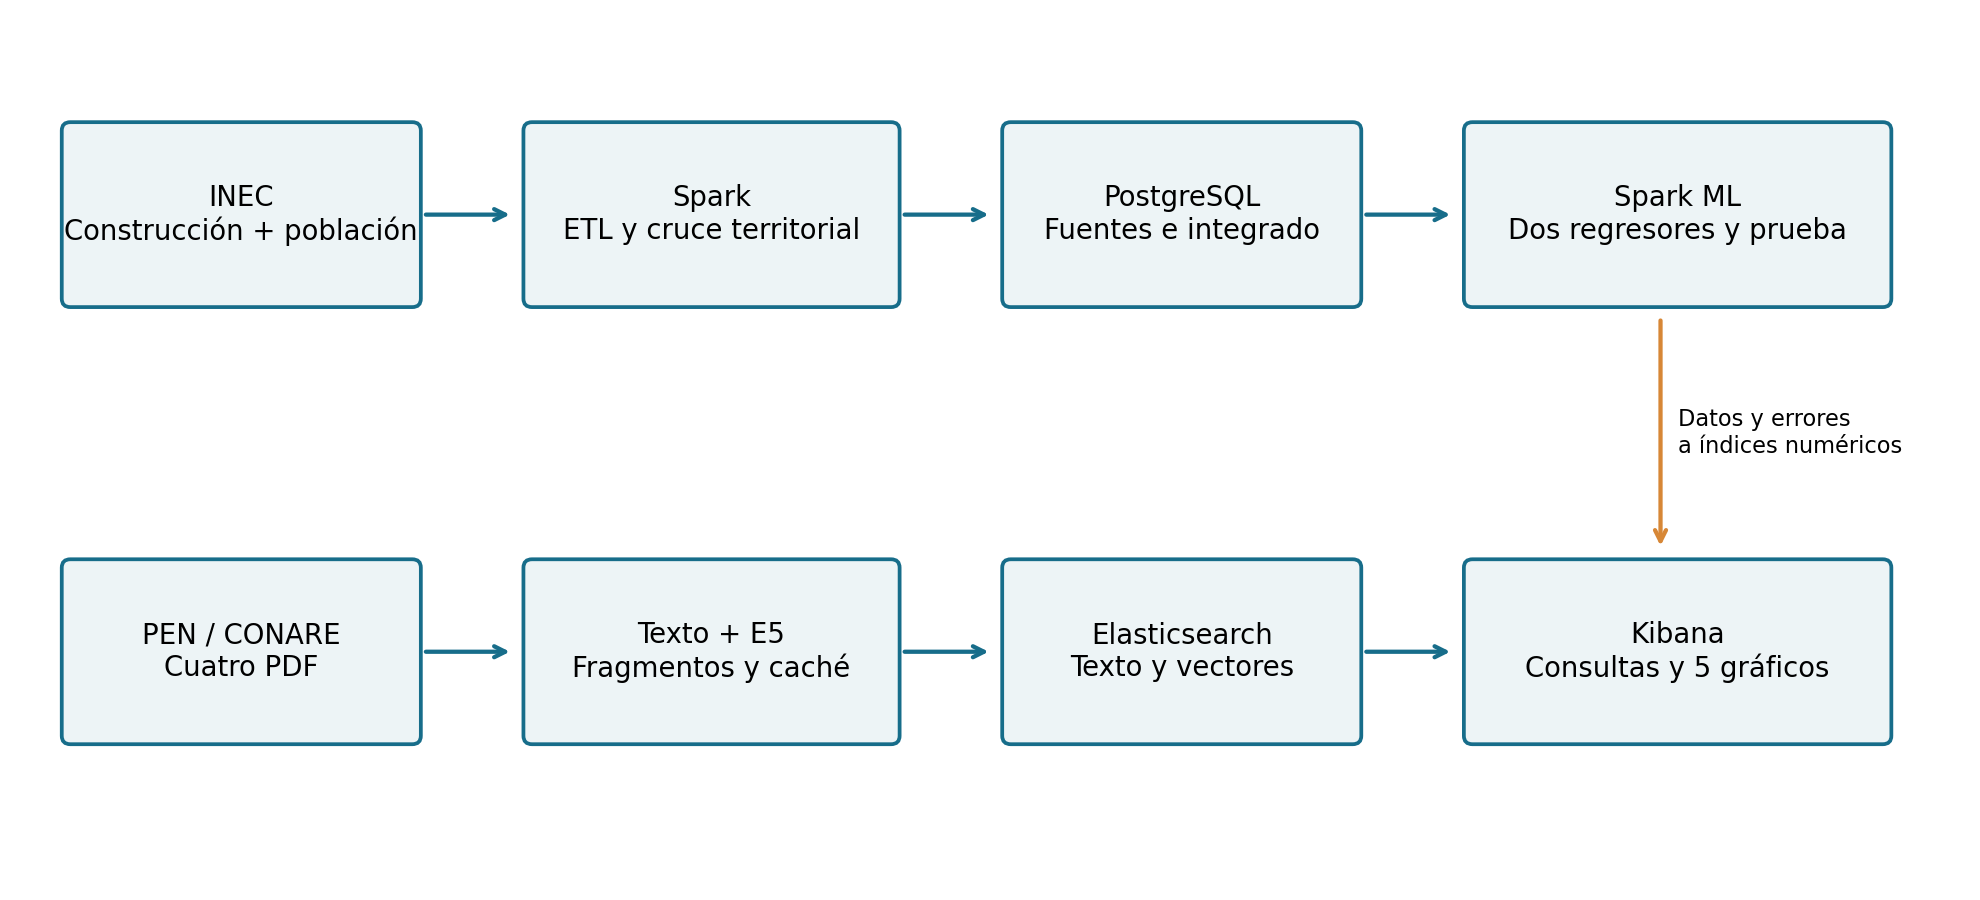

[Abrir dashboard local](http://127.0.0.1:5604/app/dashboards#/view/cp-dashboard)

Recorrido y comprobaciones terminados.


In [10]:
display(Image(filename=str(O/'graficos/arquitectura.png')))
display(Markdown('[Abrir dashboard local](http://127.0.0.1:5604/app/dashboards#/view/cp-dashboard)'))
spark.stop()
print('Recorrido y comprobaciones terminados.')